# RNN sentiment classification — Colab GPU runtime

This notebook is intended to be opened locally in VS Code and executed with the Google Colab extension connected to a Colab runtime.

The notebook uses:
- The Python source code in the GitHub repository.
- The IMDb dataset stored in Google Drive.
- A CUDA GPU when the connected runtime provides one, otherwise CPU.

**Before running:** in Colab, choose a runtime with a GPU (Runtime → Change runtime type → T4 GPU, or another available GPU). In VS Code, connect this notebook to that Colab runtime.


## 1. Connect the runtime to the project and Google Drive

The Colab runtime has its own filesystem. It does not automatically have access to every file in your local VS Code workspace. This cell clones the repository into the runtime so that imports from `src/` work.

If the repository is already cloned in this runtime, it updates the clone with `git pull`.

The dataset is not in the repository (it is excluded by `.gitignore`), so we mount Google Drive separately.


In [3]:
import sys
import subprocess
from pathlib import Path

REPO_URL = "https://github.com/NencioniTommaso/DeepSentimentClassification.git"
PROJECT_ROOT = Path("/content/DeepSentimentClassification")

if PROJECT_ROOT.exists():
    subprocess.run(
        ["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only"],
        check=True
    )
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(PROJECT_ROOT)],
        check=True
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


from pathlib import Path
import tarfile
import urllib.request

DATA_ROOT = Path("/content/aclImdb")
ARCHIVE_PATH = Path("/content/aclImdb_v1.tar.gz")

DATA_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

if not DATA_ROOT.exists():
    print("Downloading IMDb dataset...")

    urllib.request.urlretrieve(DATA_URL, ARCHIVE_PATH)

    print("Extracting dataset...")

    with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:
        archive.extractall("/content")

    ARCHIVE_PATH.unlink()

print("Dataset ready:", DATA_ROOT)


Dataset ready: /content/aclImdb


## 2. Imports and device

A Colab GPU runtime makes CUDA available, but PyTorch does not move models or batches to the GPU automatically. We select the device here and will explicitly move both the model and each batch to it during training and evaluation.


In [4]:
import random
from functools import partial

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split

from src.data.dataset import IMDbDataset
from src.data.tokenizer import WhitespaceTokenizer
from src.data.vocabulary import Vocabulary
from src.data.preprocessing import collate_fn
from src.models.rnn import RNN

SEED = 42

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.14.1+cu130
Selected device: cuda
GPU: Tesla T4


## 3. Load the IMDb dataset and create a validation split

The official test set remains untouched until the final evaluation. We split 10% of the official training set for validation.


In [5]:
train_dataset = IMDbDataset(DATA_ROOT, train=True)
test_dataset = IMDbDataset(DATA_ROOT, train=False)

print(f"Training examples available: {len(train_dataset)}")
print(f"Test examples: {len(test_dataset)}")

train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size

generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=generator
)

print(f"Training subset: {len(train_subset)}")
print(f"Validation subset: {len(val_subset)}")


Training examples available: 25000
Test examples: 25000
Training subset: 22500
Validation subset: 2500


## 4. Build the vocabulary

Build the vocabulary only from the training subset. Validation and test reviews must not influence the vocabulary.

`min_freq=2` keeps tokens that occur at least twice in the training subset.


In [6]:
tokenizer = WhitespaceTokenizer()
vocab = Vocabulary(tokenizer, min_freq=2)

vocab.build([review for review, _ in train_subset])

print("Vocabulary size (including special tokens):", len(vocab))


Vocabulary size (including special tokens): 102801


## 5. Create the DataLoaders

`collate_fn` converts raw reviews to token IDs and pads the reviews in each batch to the length of the longest review in that batch.

`MAX_LENGTH` is optional:
- `None` preserves the current preprocessing behavior and uses the longest sequence in each batch.
- An integer truncates longer reviews and pads shorter ones to that fixed length.

Start with `None` to preserve the original notebook's setup. If training is too slow, try a fixed value such as `512`, understanding that this discards tokens beyond that length.


In [7]:
BATCH_SIZE = 32
MAX_LENGTH = None

collate = partial(
    collate_fn,
    vocab=vocab,
    max_length=MAX_LENGTH
)

# Pinned memory can speed up host-to-GPU transfers when CUDA is used.
pin_memory = device.type == "cuda"

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate,
    pin_memory=pin_memory,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate,
    pin_memory=pin_memory,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate,
    pin_memory=pin_memory,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 704
Validation batches: 79
Test batches: 782


## 6. Define the RNN model

The model returns two logits per review (negative and positive). We use `CrossEntropyLoss`, so do not add a Softmax layer to the model.

The model is moved to the selected device with `model.to(device)`.


In [8]:
model = RNN(
    vocab_size=len(vocab),
    embedding_size=100,
    hidden_size=128,
    output_size=2
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Model device:", next(model.parameters()).device)


Model device: cuda:0


## 7. Train and validate

Both `inputs` and `labels` must be moved to the same device as the model. The RNN processes the sequence one token at a time in Python, so using a GPU does not guarantee a large speed-up; the recurrent computation is sequential.


In [9]:
NUM_EPOCHS = 10

train_losses = []
val_losses = []
val_accuracies = []

best_val_loss = float("inf")

# Save checkpoints in Google Drive so they survive a Colab runtime reset.
SAVE_DIR = Path("/content/saved_models")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = SAVE_DIR / "best_single_rnn_model.pth"

for epoch in range(NUM_EPOCHS):
    # Training
    model.train()
    running_train_loss = 0.0

    for inputs, labels in train_loader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)

    # Validation
    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    avg_val_loss = running_val_loss / len(val_loader)
    val_accuracy = correct / total

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    val_accuracies.append(val_accuracy)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), MODEL_PATH)
        print(f"Best model saved to: {MODEL_PATH}")

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )


Best model saved to: /content/saved_models/best_single_rnn_model.pth
Epoch 1/10 | Train Loss: 0.6871 | Val Loss: 0.6723 | Val Accuracy: 0.5828
Best model saved to: /content/saved_models/best_single_rnn_model.pth
Epoch 2/10 | Train Loss: 0.6522 | Val Loss: 0.6504 | Val Accuracy: 0.6136
Best model saved to: /content/saved_models/best_single_rnn_model.pth
Epoch 3/10 | Train Loss: 0.6099 | Val Loss: 0.6451 | Val Accuracy: 0.6232
Epoch 4/10 | Train Loss: 0.5970 | Val Loss: 0.6549 | Val Accuracy: 0.6128
Best model saved to: /content/saved_models/best_single_rnn_model.pth
Epoch 5/10 | Train Loss: 0.5194 | Val Loss: 0.6432 | Val Accuracy: 0.6740
Epoch 6/10 | Train Loss: 0.4470 | Val Loss: 0.6993 | Val Accuracy: 0.6668
Epoch 7/10 | Train Loss: 0.3809 | Val Loss: 0.6972 | Val Accuracy: 0.7004
Epoch 8/10 | Train Loss: 0.3300 | Val Loss: 0.6899 | Val Accuracy: 0.6996
Epoch 9/10 | Train Loss: 0.3209 | Val Loss: 0.7254 | Val Accuracy: 0.7152
Epoch 10/10 | Train Loss: 0.3209 | Val Loss: 0.7207 | Val 

## 8. Plot the learning curves


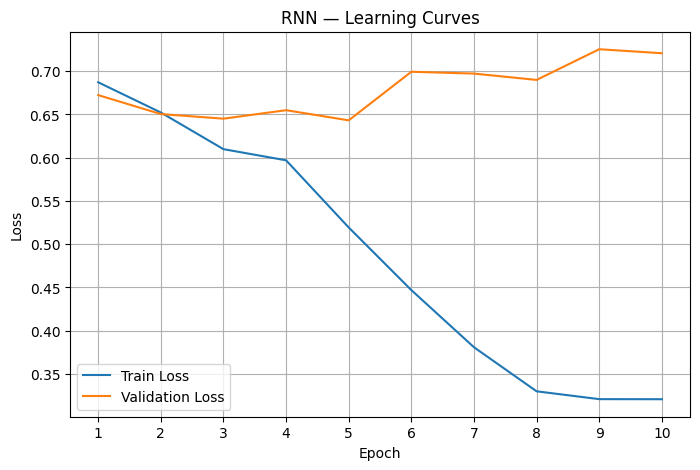

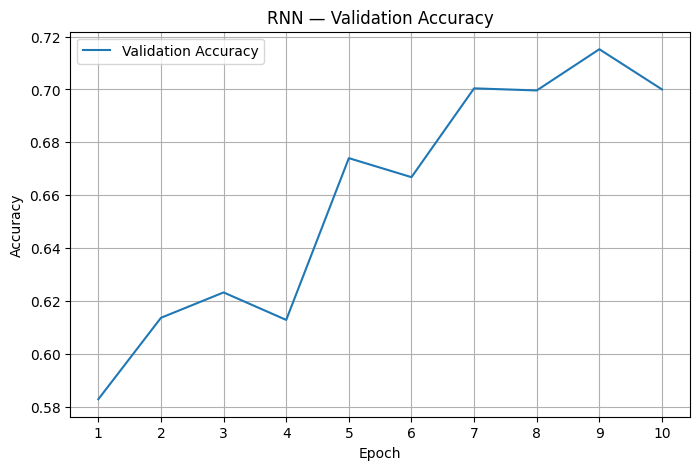

In [10]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN — Learning Curves")
plt.xticks(list(epochs))
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN — Validation Accuracy")
plt.xticks(list(epochs))
plt.grid(True)
plt.legend()
plt.show()


## 9. Evaluate on the official test set

Load the best checkpoint selected by validation loss, then evaluate it once on the test set. `map_location=device` ensures the checkpoint is loaded onto the currently selected device.


In [11]:
model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)
model.to(device)
model.eval()

test_loss_total = 0.0
correct = 0
total = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        test_loss_total += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

avg_test_loss = test_loss_total / len(test_loader)
test_accuracy = correct / total

print(f"Test Loss: {avg_test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Test Loss: 0.6497
Test Accuracy: 0.6641


In [12]:
from google.colab import files

files.download(str(MODEL_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes

- The source code is imported from the repository clone at `/content/DeepSentimentClassification`. If you change a Python file locally in VS Code, commit and push that change to GitHub before rerunning this notebook; the setup cell pulls the latest commit when the runtime reconnects.
- The notebook itself can remain local in your VS Code workspace.
- If the GPU runs out of memory, reduce `BATCH_SIZE`. If training is too slow, experiment with `MAX_LENGTH`, but remember that truncating reviews changes the input information available to the model.
